# Tutorial de CLASS
*Cosmic Linear Anisotropy Solving System* — resuelve las ecuaciones de Einstein–Boltzmann linealizadas.

Instalación (sólo la primera vez):

In [ ]:
%pip install classy scipy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
from classy import Class

## 1. Parámetros cosmológicos
CLASS recibe un diccionario. Los parámetros no especificados toman valores por defecto.

**¿Hay que decirle a CLASS qué calcular?**
- Sin `output`, CLASS resuelve sólo la parte homogénea (background y termodinámica): alcanza para $H(z)$, distancias, $x_e$, $\kappa$, $g$.
- Las perturbaciones (Einstein–Boltzmann) se integran sólo si se piden: `'output': 'mPk'` es necesario para $P(k)$ y $\sigma_8$, y sólo en el rango dado por `P_k_max_1/Mpc` y `z_max_pk` (fuera de ese rango, error).
- Se puede agregar un output después con `cosmo.set({...})` y volver a correr `cosmo.compute()`.

In [2]:
params = {
    # ΛCDM (Planck 2018)
    'h': 0.6736,              # H0 = 100 h km/s/Mpc
    'omega_b': 0.02237,       # Ω_b h²
    'omega_cdm': 0.1200,      # Ω_cdm h²
    'A_s': 2.1e-9,            # amplitud del espectro primordial
    'n_s': 0.9649,            # índice espectral
    'tau_reio': 0.0544,       # profundidad óptica de reionización
    # qué calcular
    'output': 'mPk',          # espectro de potencia de materia
    'P_k_max_1/Mpc': 10.0,    # k máximo [1/Mpc]
    'z_max_pk': 5.0,          # z máximo para P(k,z)
}

## 2. Resolver las ecuaciones

In [3]:
cosmo = Class()
cosmo.set(params)
cosmo.compute()

In [4]:
der = cosmo.get_current_derived_parameters(
    ['Omega_m', 'Omega_Lambda', 'age', 'z_eq', 'k_eq', 'z_reio', 'z_star', 'z_d', 'sigma8'])
for k, v in der.items():
    print(f'{k:14s} {v:.5g}')

Omega_m        0.31377
Omega_Lambda   0.68614
age            13.814
z_eq           3402.9
k_eq           0.010385
z_reio         7.6785
z_star         1085.1
z_d            1059.9
sigma8         0.82291


- `z_eq`, `k_eq`: igualdad materia–radiación
- `z_star`: último scattering (máximo de la visibilidad)
- `z_d`: fin del *drag* de bariones
- `age` en Gyr, `k_eq` en 1/Mpc

## 3. Background (cosmología homogénea)
`get_background()` devuelve un diccionario de arrays tabulados en z.

In [5]:
bg = cosmo.get_background()
print(list(bg.keys()))

['z', 'proper time [Gyr]', 'conf. time [Mpc]', 'H [1/Mpc]', 'comov. dist.', 'ang.diam.dist.', 'lum. dist.', 'comov.snd.hrz.', '(.)rho_g', '(.)rho_b', '(.)rho_cdm', '(.)rho_lambda', '(.)rho_ur', '(.)rho_crit', '(.)rho_tot', '(.)p_tot', '(.)p_tot_prime', 'Omega_r(z)', 'Omega_m(z)', 'gr.fac. D', 'gr.fac. f']


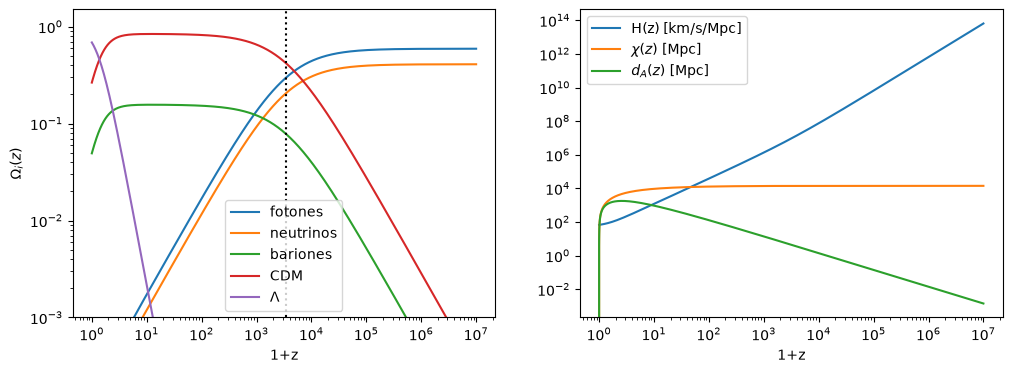

In [6]:
m = bg['z'] < 1e7
bg = {key: val[m] for key, val in bg.items()}
z = bg['z']
H = bg['H [1/Mpc]']                  # H(z)/c
rho = {s: bg[f'(.)rho_{s}'] for s in ['g', 'ur', 'b', 'cdm', 'lambda']}
rho_tot = bg['(.)rho_crit']

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s, label in zip(rho, ['fotones', 'neutrinos', 'bariones', 'CDM', 'Λ']):
    ax[0].loglog(1 + z, rho[s] / rho_tot, label=label)
ax[0].axvline(1 + der['z_eq'], c='k', ls=':')
ax[0].set(xlabel='1+z', ylabel=r'$\Omega_i(z)$', ylim=(1e-3, 1.5))
ax[0].legend()

ax[1].loglog(1 + z, H * 299792.458, label='H(z) [km/s/Mpc]')
ax[1].loglog(1 + z, bg['comov. dist.'], label=r'$\chi(z)$ [Mpc]')
ax[1].loglog(1 + z, bg['ang.diam.dist.'], label=r'$d_A(z)$ [Mpc]')
ax[1].set(xlabel='1+z')
ax[1].legend()
plt.show()

También hay funciones directas: `cosmo.Hubble(z)` [1/Mpc], `cosmo.angular_distance(z)`, `cosmo.luminosity_distance(z)` [Mpc].

In [8]:
print('H0 =', cosmo.Hubble(0) * 299792.458, 'km/s/Mpc')
dA = cosmo.angular_distance(der['z_star'])
print('d_A(z*) =', dA, 'Mpc  (comóvil:', dA * (1 + der['z_star']), 'Mpc)')

H0 = 67.36 km/s/Mpc
d_A(z*) = 12.791481128739926 Mpc  (comóvil: 13893.142517310534 Mpc)


## 4. Termodinámica: ionización, profundidad óptica y visibilidad

- $x_e(z)$: fracción de ionización
- $\kappa(\eta) = \int_\eta^{\eta_0} a\, n_e \sigma_T\, d\eta'$: profundidad óptica desde hoy hasta $\eta$
- $g(\eta) = \kappa'\, e^{-\kappa}$: función de visibilidad (probabilidad de que un fotón haya sido dispersado por última vez en $\eta$)

In [9]:
th = cosmo.get_thermodynamics()
print(list(th.keys()))

['scale factor a', 'z', 'conf. time [Mpc]', 'x_e', "kappa' [Mpc^-1]", 'exp(-kappa)', 'g [Mpc^-1]', 'Tb [K]', 'dTb [K]', 'w_b', 'c_b^2', 'kappa_b']


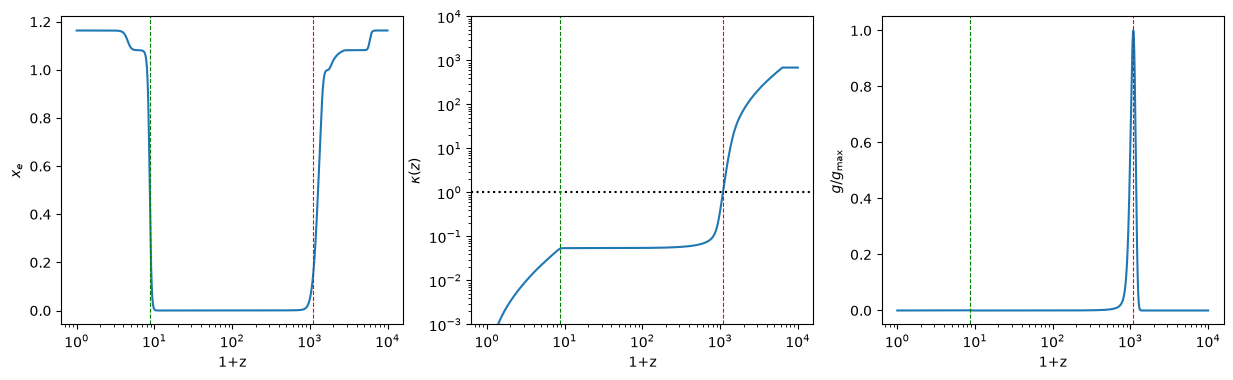

In [10]:
m   = th['z'] < 1e4
th  = {key: val[m] for key, val in th.items()}
zt  = th['z']
xe  = th['x_e']
tau = -np.log(np.maximum(th['exp(-kappa)'], 1e-300))     # profundidad óptica κ(z)
g   = th['g [Mpc^-1]']               # visibilidad (por unidad de tiempo conforme)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].semilogx(1 + zt, xe)
ax[0].set(xlabel='1+z', ylabel=r'$x_e$')

ax[1].loglog(1 + zt, tau)
ax[1].axhline(1, c='k', ls=':')
ax[1].set(xlabel='1+z', ylabel=r'$\kappa(z)$', ylim=(1e-3, 1e4))

ax[2].semilogx(1 + zt, g / g.max())
ax[2].set(xlabel='1+z', ylabel=r'$g / g_{\max}$')
for a in ax:
    a.axvline(1 + der['z_star'], c='r', ls='--', lw=0.8)
    a.axvline(1 + der['z_reio'], c='g', ls='--', lw=0.8)
plt.show()

La visibilidad tiene un pico en $z_*$ (recombinación) y un segundo pico, mucho menor, en reionización. Zoom en ese segundo pico:

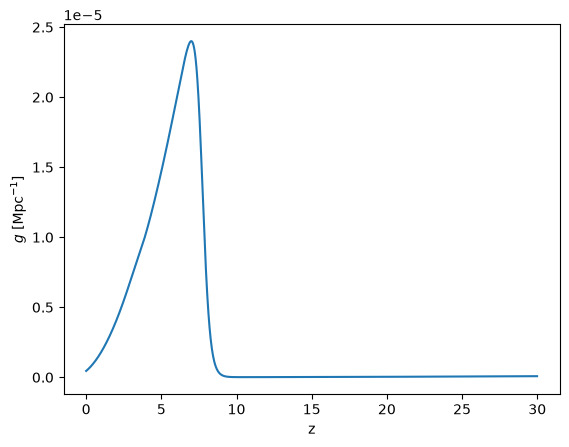

κ(z_reio→0) = 0.05445738805090976  vs  tau_reio = 0.0544


In [11]:
m = zt < 30
plt.plot(zt[m], g[m])
plt.xlabel('z'); plt.ylabel(r'$g$ [Mpc$^{-1}$]')
plt.show()

print('κ(z_reio→0) =', np.interp(30, zt, tau), ' vs  tau_reio =', params['tau_reio'])

## 5. Espectro de potencia de materia
`cosmo.pk_lin(k, z)` devuelve $P(k,z)$ lineal, con $k$ en 1/Mpc y $P$ en Mpc³.
Convertimos a las unidades usuales: $k$ [h/Mpc], $P$ [(Mpc/h)³].

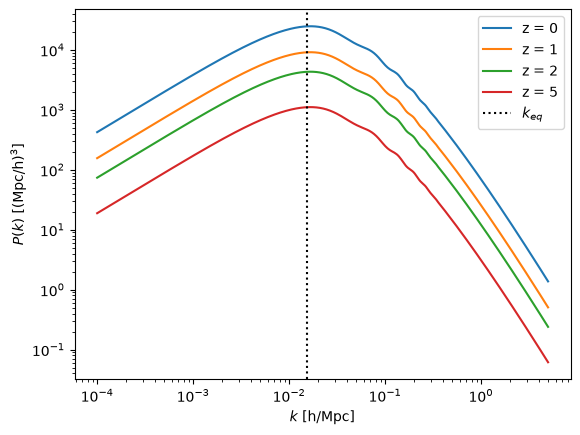

In [12]:
h = cosmo.h()
kh = np.logspace(-4, np.log10(5), 400)     # h/Mpc

def Pk(c, kh, z=0):
    return np.array([c.pk_lin(k * c.h(), z) for k in kh]) * c.h()**3

zs = [0, 1, 2, 5]
for zz in zs:
    plt.loglog(kh, Pk(cosmo, kh, zz), label=f'z = {zz}')
plt.axvline(der['k_eq'] / h, c='k', ls=':', label=r'$k_{eq}$')
plt.xlabel(r'$k$ [h/Mpc]'); plt.ylabel(r'$P(k)$ [(Mpc/h)$^3$]')
plt.legend(); plt.show()

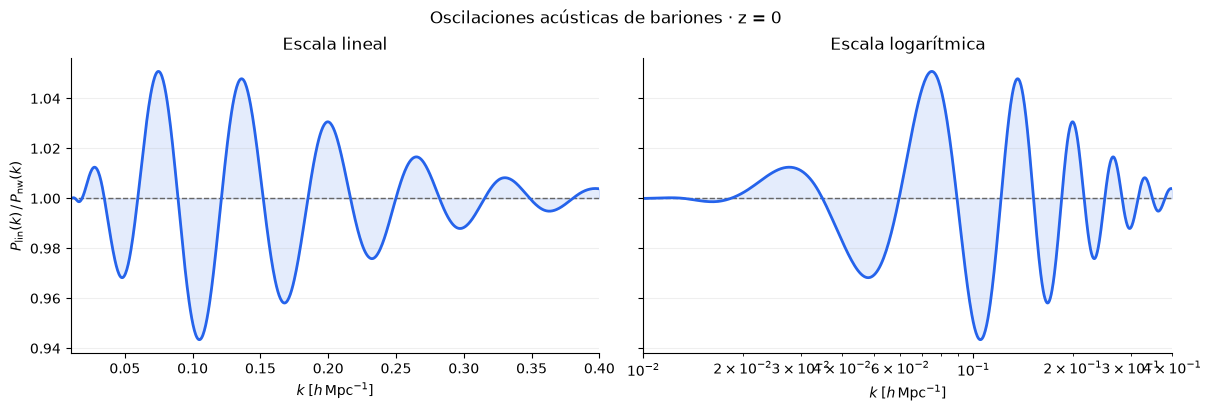

In [13]:
# BAO: espectro lineal completo / espectro suavizado, para la misma cosmología.
c_bao = Class()
c_bao.set({**params, 'numerical_nowiggle': 'yes'})
c_bao.compute()

k_bao = np.linspace(0.01, 0.4, 800)  # h/Mpc
h_bao = c_bao.h()
P_bao = np.array([c_bao.pk_lin(k * h_bao, 0) for k in k_bao])
P_nw = np.array([c_bao.pk_numerical_nw(k * h_bao, 0) for k in k_bao])
ratio_bao = P_bao / P_nw  # La conversión de unidades se cancela en el cociente.
c_bao.struct_cleanup()
c_bao.empty()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True,
                         constrained_layout=True)
for ax, scale, title in zip(axes, ['linear', 'log'],
                            ['Escala lineal', 'Escala logarítmica']):
    ax.axhline(1, color='0.4', ls='--', lw=1)
    ax.plot(k_bao, ratio_bao, color='#2563eb', lw=2)
    ax.fill_between(k_bao, 1, ratio_bao, color='#2563eb', alpha=0.12)
    ax.set(xscale=scale, xlabel=r'$k\;[h\,\mathrm{Mpc}^{-1}]$',
           title=title, xlim=(k_bao[0], k_bao[-1]))
    ax.grid(axis='y', alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel(r'$P_{\mathrm{lin}}(k)\,/\,P_{\mathrm{nw}}(k)$')
fig.suptitle('Oscilaciones acústicas de bariones · z = 0')
plt.show()


### Crecimiento lineal
En teoría lineal $P(k,z) = D^2(z)\,P(k,0)$ en escalas sub-horizonte.

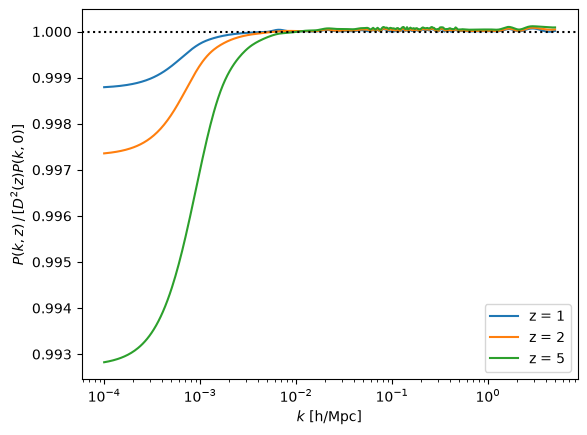

In [14]:
for zz in zs[1:]:
    D = cosmo.scale_independent_growth_factor(zz)
    plt.semilogx(kh, Pk(cosmo, kh, zz) / Pk(cosmo, kh, 0) / D**2, label=f'z = {zz}')
plt.axhline(1, c='k', ls=':')
plt.xlabel(r'$k$ [h/Mpc]'); plt.ylabel(r'$P(k,z) \,/\, [D^2(z) P(k,0)]$')
plt.legend(); plt.show()

### $\sigma_8$
Varianza del campo de densidad suavizado con un top-hat de $R = 8\,h^{-1}$Mpc:
$\sigma_R^2 = \int \frac{k^2 dk}{2\pi^2} P(k) W^2(kR)$

In [15]:
def sigma_R(c, R, z=0):
    k = np.logspace(-4, np.log10(5), 2000)          # h/Mpc
    x = k * R
    W = 3 * (np.sin(x) - x * np.cos(x)) / x**3
    return np.sqrt(trapezoid(k**2 * Pk(c, k, z) * W**2, k) / (2 * np.pi**2))

print('σ8 (integral) =', sigma_R(cosmo, 8.0))
print('σ8 (CLASS)    =', cosmo.sigma8())

σ8 (integral) = 0.8229088366800356
σ8 (CLASS)    = 0.8229091030815184


### Dependencia con los parámetros
Función auxiliar: corre CLASS cambiando algún parámetro y devuelve $P(k)$.

In [16]:
def run(**cambios):
    c = Class()
    c.set({**params, **cambios})
    c.compute()
    P = Pk(c, kh)
    c.struct_cleanup(); c.empty()
    return P

P0 = Pk(cosmo, kh)

**Densidad de materia oscura** $\omega_{cdm}$: desplaza la igualdad materia–radiación y por lo tanto el pico de $P(k)$.

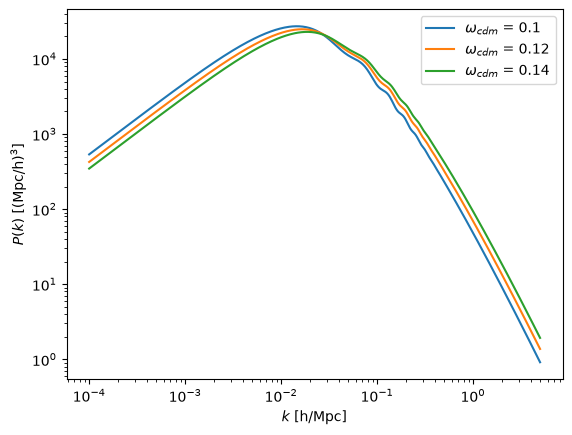

In [17]:
for w in [0.10, 0.12, 0.14]:
    plt.loglog(kh, run(omega_cdm=w), label=rf'$\omega_{{cdm}}$ = {w}')
plt.xlabel(r'$k$ [h/Mpc]'); plt.ylabel(r'$P(k)$ [(Mpc/h)$^3$]')
plt.legend(); plt.show()

**Bariones** $\omega_b$: oscilaciones acústicas (BAO) y supresión en escalas pequeñas.
Se ve mejor en el cociente respecto a un modelo sin bariones (casi).

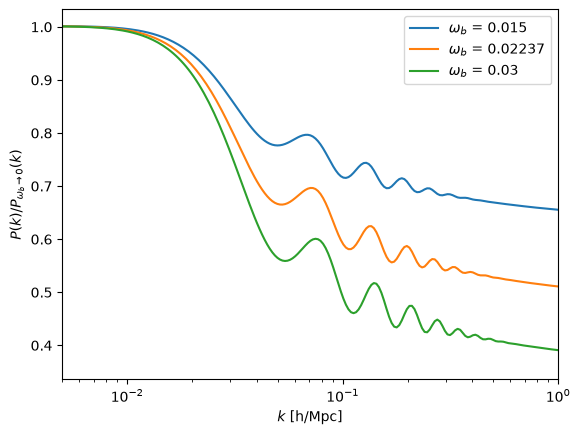

In [18]:
P_nob = run(omega_b=0.002, YHe=0.245, omega_cdm=params['omega_cdm'] + params['omega_b'] - 0.002)
for wb in [0.015, 0.02237, 0.03]:
    P = run(omega_b=wb, omega_cdm=params['omega_cdm'] + params['omega_b'] - wb)
    plt.semilogx(kh, P / P_nob, label=rf'$\omega_b$ = {wb}')
plt.xlim(5e-3, 1)
plt.xlabel(r'$k$ [h/Mpc]'); plt.ylabel(r'$P(k) / P_{\omega_b\to 0}(k)$')
plt.legend(); plt.show()

**Neutrinos masivos**: suprimen el crecimiento por debajo de la escala de free-streaming ($\Delta P/P \approx -8 f_\nu$).

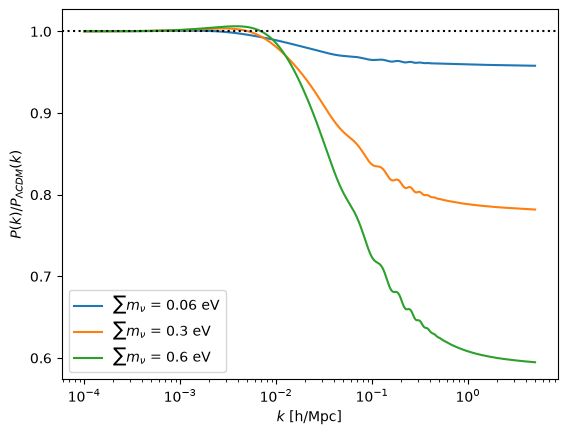

In [19]:
for mnu in [0.06, 0.3, 0.6]:
    P = run(N_ur=2.0328, N_ncdm=1, m_ncdm=mnu,
            omega_cdm=params['omega_cdm'] - mnu / 93.14)
    plt.semilogx(kh, P / P0, label=rf'$\sum m_\nu$ = {mnu} eV')
plt.axhline(1, c='k', ls=':')
plt.xlabel(r'$k$ [h/Mpc]'); plt.ylabel(r'$P(k) / P_{\Lambda CDM}(k)$')
plt.legend(); plt.show()

### Lineal vs no lineal
Con `'non_linear': 'halofit'`, `cosmo.pk(k, z)` devuelve el espectro no lineal.

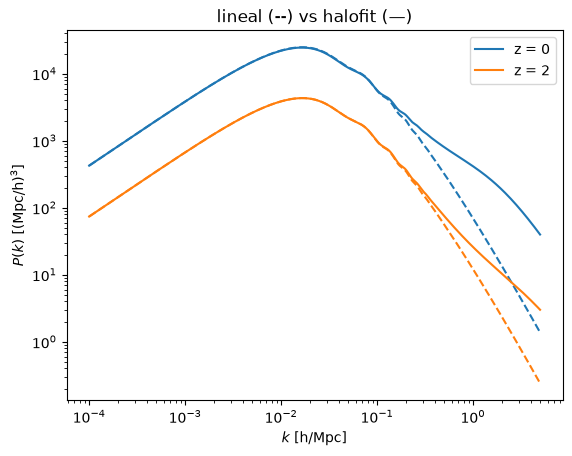

In [20]:
cnl = Class()
cnl.set({**params, 'non_linear': 'halofit'})
cnl.compute()

for zz, col in zip([0, 2], ['C0', 'C1']):
    Pnl = np.array([cnl.pk(k * h, zz) for k in kh]) * h**3
    plt.loglog(kh, Pk(cnl, kh, zz), c=col, ls='--')
    plt.loglog(kh, Pnl, c=col, label=f'z = {zz}')
plt.xlabel(r'$k$ [h/Mpc]'); plt.ylabel(r'$P(k)$ [(Mpc/h)$^3$]')
plt.title('lineal (--) vs halofit (—)')
plt.legend(); plt.show()

## Limpieza

In [21]:
for c in [cosmo, cnl]:
    c.struct_cleanup(); c.empty()